cell_1:Set up the notebook

In [29]:
!pip -q install scanpy

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy import sparse

DATA_PATH = Path(
    "/content/drive/MyDrive/spatial_transcriptomics/"
    "xenium_breast_cancer.h5ad"
)

RESULTS_DIR = Path(
    "/content/drive/MyDrive/spatial_transcriptomics/results"
)
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(DATA_PATH)

print("Dataset loaded successfully")
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Output folder:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully
Cells: 167780
Genes: 313
Output folder: /content/drive/MyDrive/spatial_transcriptomics/results


Cell 2 — Verify dataset integrity

In [30]:
print("Dataset shape:", adata.shape)
print("\nObservation columns:")
print(adata.obs.columns.tolist())

print("\nVariable names unique:", adata.var_names.is_unique)
print("Cell identifiers unique:", adata.obs_names.is_unique)

print("\nMissing values per observation column:")
print(adata.obs.isna().sum().to_string())

assert "spatial" in adata.obsm, "Spatial coordinates are missing"

coords = np.asarray(adata.obsm["spatial"])

print("\nSpatial coordinate shape:", coords.shape)
print("Missing coordinate values:", np.isnan(coords).sum())
print("Non-finite coordinate values:", (~np.isfinite(coords)).sum())

assert coords.shape == (adata.n_obs, 2)
assert np.isfinite(coords).all(), "Check invalid spatial coordinates"

Dataset shape: (167780, 313)

Observation columns:
['total_transcripts', 'detected_genes', 'x_centroid', 'y_centroid', 'cell_area', 'nucleus_area', 'transcript_counts']

Variable names unique: True
Cell identifiers unique: True

Missing values per observation column:
total_transcripts    0
detected_genes       0
x_centroid           0
y_centroid           0
cell_area            0
nucleus_area         0
transcript_counts    0

Spatial coordinate shape: (167780, 2)
Missing coordinate values: 0
Non-finite coordinate values: 0


Cell 3 — Summarize cell-level quality metrics

In [31]:
qc_columns = [
    col for col in [
        "total_transcripts",
        "transcript_counts",
        "detected_genes",
        "cell_area",
        "nucleus_area",
    ]
    if col in adata.obs.columns
]

qc_summary = (
    adata.obs[qc_columns]
    .apply(pd.to_numeric, errors="coerce")
    .describe()
    .T
)

print(qc_summary.round(2).to_string())

qc_summary.to_csv(RESULTS_DIR / "qc_summary.csv")

                      count    mean     std   min    25%     50%     75%      max
total_transcripts  167780.0  191.34  129.43  0.00  96.00  164.00  262.00  1359.00
transcript_counts  167780.0  191.34  129.43  0.00  96.00  164.00  262.00  1359.00
detected_genes     167780.0   63.20   24.55  0.00  48.00   64.00   79.00   194.00
cell_area          167780.0  193.67  174.44  5.19  86.02  140.30  229.53  1532.74
nucleus_area       167780.0   43.08   30.68  3.21  22.08   33.24   57.30   392.50


Cell 4 — Visualize quality distributions

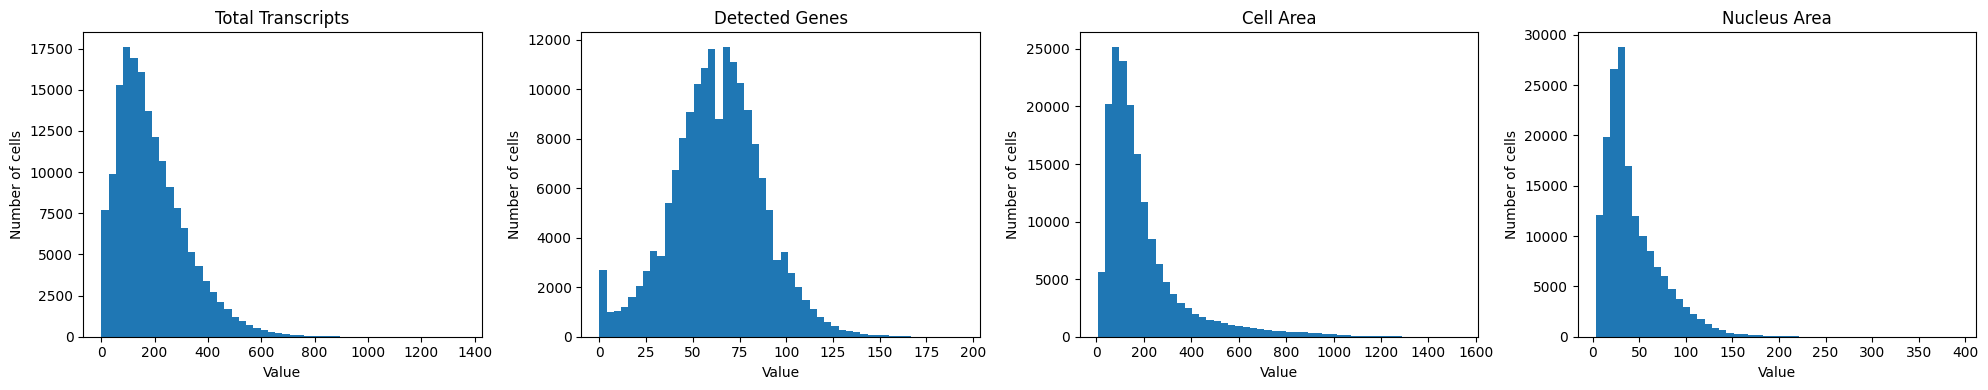

In [32]:
metrics = [
    col for col in [
        "total_transcripts",
        "detected_genes",
        "cell_area",
        "nucleus_area",
    ]
    if col in adata.obs.columns
]

fig, axes = plt.subplots(
    1, len(metrics), figsize=(5 * len(metrics), 4)
)

axes = np.atleast_1d(axes)

for ax, col in zip(axes, metrics):
    values = pd.to_numeric(
        adata.obs[col], errors="coerce"
    ).dropna()

    ax.hist(values, bins=50)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of cells")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "qc_metric_distributions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Cell 5 — Check marker-gene availability

In [33]:
marker_groups = {
    "epithelial_associated": ["EPCAM", "KRT8"],
    "t_cell_associated": ["CD3D", "CD3E"],
    "immune_associated": ["PTPRC", "CD68", "MS4A1"],
    "stromal_vascular_associated": ["ACTA2", "PECAM1"],
}

available_genes = set(adata.var_names)

marker_availability = pd.DataFrame([
    {
        "marker_group": group,
        "gene": gene,
        "available": gene in available_genes,
    }
    for group, genes in marker_groups.items()
    for gene in genes
])

print(marker_availability.to_string(index=False))

marker_availability.to_csv(
    RESULTS_DIR / "marker_gene_availability.csv",
    index=False
)

               marker_group   gene  available
      epithelial_associated  EPCAM       True
      epithelial_associated   KRT8       True
          t_cell_associated   CD3D       True
          t_cell_associated   CD3E       True
          immune_associated  PTPRC       True
          immune_associated   CD68       True
          immune_associated  MS4A1       True
stromal_vascular_associated  ACTA2       True
stromal_vascular_associated PECAM1       True


Cell 6 — Calculate marker detection statistics

In [34]:
def get_expression(gene):
    """Return one gene's expression values as a NumPy array."""
    if gene not in adata.var_names:
        raise ValueError(f"{gene} is not present in this dataset")

    values = adata[:, gene].X

    if sparse.issparse(values):
        values = values.toarray()

    return np.asarray(values).ravel()


marker_rows = []

for group, genes in marker_groups.items():
    for gene in genes:
        if gene not in available_genes:
            continue

        values = get_expression(gene)
        detected = values > 0

        marker_rows.append({
            "marker_group": group,
            "gene": gene,
            "cells_detected": int(detected.sum()),
            "percent_cells_detected": float(
                detected.mean() * 100
            ),
            "mean_expression": float(values.mean()),
        })

marker_summary = pd.DataFrame(marker_rows)

print(marker_summary.round(3).to_string(index=False))

marker_summary.to_csv(
    RESULTS_DIR / "marker_detection_summary.csv",
    index=False
)

               marker_group   gene  cells_detected  percent_cells_detected  mean_expression
      epithelial_associated  EPCAM           97872                  58.334            4.245
      epithelial_associated   KRT8           94250                  56.175            3.094
          t_cell_associated   CD3D           19390                  11.557            0.166
          t_cell_associated   CD3E           40249                  23.989            0.601
          immune_associated  PTPRC           58747                  35.014            0.975
          immune_associated   CD68           52419                  31.243            0.815
          immune_associated  MS4A1            7928                   4.725            0.117
stromal_vascular_associated  ACTA2           94179                  56.132            1.894
stromal_vascular_associated PECAM1           42764                  25.488            0.713


Cell 7 — Summarize marker groups

In [35]:
group_rows = []

for group, genes in marker_groups.items():
    present = [g for g in genes if g in available_genes]

    if not present:
        continue

    detected_matrix = np.column_stack([
        get_expression(g) > 0 for g in present
    ])

    any_positive = detected_matrix.any(axis=1)
    all_positive = detected_matrix.all(axis=1)

    group_rows.append({
        "marker_group": group,
        "markers_available": ", ".join(present),
        "cells_with_any_marker": int(any_positive.sum()),
        "cells_with_all_markers": int(all_positive.sum()),
        "percent_with_any_marker": float(
            any_positive.mean() * 100
        ),
    })

group_summary = pd.DataFrame(group_rows)

print(group_summary.round(2).to_string(index=False))

group_summary.to_csv(
    RESULTS_DIR / "marker_group_summary.csv",
    index=False
)

               marker_group  markers_available  cells_with_any_marker  cells_with_all_markers  percent_with_any_marker
      epithelial_associated        EPCAM, KRT8                 112065                   80057                    66.79
          t_cell_associated         CD3D, CD3E                  44636                   15003                    26.60
          immune_associated PTPRC, CD68, MS4A1                  83094                    2841                    49.53
stromal_vascular_associated      ACTA2, PECAM1                 107852                   29091                    64.28


Cell 8 — Add non-destructive QC flags

In [36]:
qc_flags = pd.DataFrame(index=adata.obs_names)

if "detected_genes" in adata.obs.columns:
    qc_flags["zero_detected_genes"] = (
        pd.to_numeric(
            adata.obs["detected_genes"], errors="coerce"
        ) == 0
    )

if "total_transcripts" in adata.obs.columns:
    qc_flags["zero_total_transcripts"] = (
        pd.to_numeric(
            adata.obs["total_transcripts"], errors="coerce"
        ) == 0
    )
elif "transcript_counts" in adata.obs.columns:
    qc_flags["zero_transcript_counts"] = (
        pd.to_numeric(
            adata.obs["transcript_counts"], errors="coerce"
        ) == 0
    )

for col in qc_flags.columns:
    adata.obs[col] = qc_flags[col].to_numpy()
    print(f"{col}: {int(qc_flags[col].sum())} cells flagged")

qc_flags.to_csv(RESULTS_DIR / "cell_qc_flags.csv")

zero_detected_genes: 1417 cells flagged
zero_total_transcripts: 1417 cells flagged


Cell 9 — Plot marker detection percentages

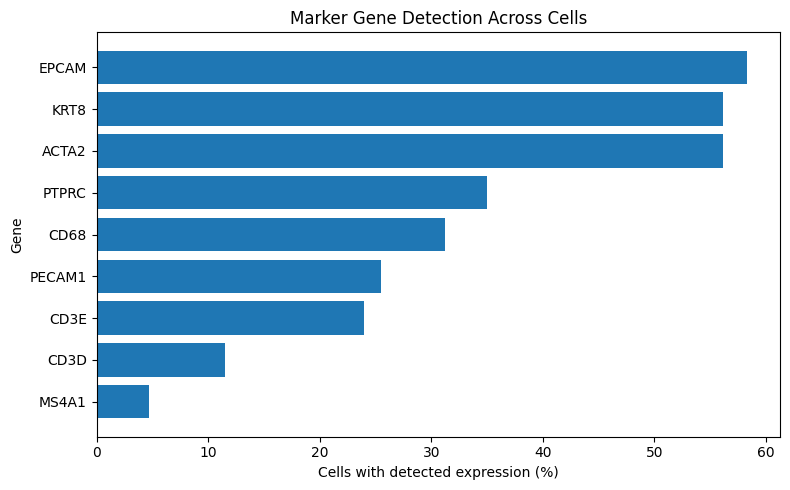

In [37]:
plot_data = marker_summary.sort_values(
    "percent_cells_detected"
)

plt.figure(figsize=(8, 5))
plt.barh(
    plot_data["gene"],
    plot_data["percent_cells_detected"]
)
plt.xlabel("Cells with detected expression (%)")
plt.ylabel("Gene")
plt.title("Marker Gene Detection Across Cells")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "marker_detection_fractions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Cell 10 — Save the final QC outputs

In [1]:
from datetime import datetime, timezone

QC_DATA_PATH = (
    "/content/drive/MyDrive/spatial_transcriptomics/"
    "xenium_breast_cancer_qc.h5ad"
)

adata.write_h5ad(QC_DATA_PATH, compression="gzip")

manifest = {
    "project": "Spatial Transcriptomics Tumor Microenvironment",
    "dataset": "Xenium FFPE Human Breast Cancer Replicate 1",
    "analysis_notebook": "02_quality_control.ipynb",
    "n_cells": int(adata.n_obs),
    "n_genes": int(adata.n_vars),
    "spatial_coordinates_present": "spatial" in adata.obsm,
    "marker_groups": marker_groups,
    "random_seed": 42,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notes": [
        "QC flags are descriptive; no cells were removed.",
        "Marker groups are exploratory and may overlap.",
        "Expression thresholds and filtering require biological justification."
    ],
}

with open(RESULTS_DIR / "analysis_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("QC notebook outputs saved.")
print("Annotated dataset:", QC_DATA_PATH)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

NameError: name 'adata' is not defined